# Capstone Project - week 2 (revised)

This version fixes issues found in review of the original week-2 draft:
- Each function's round-1 query + result (from week 1) is now appended to the training data before fitting the round-2 GP (previously round 2 was computed on the original initial data only, which caused the acquisition function to re-suggest almost the same point already queried for some functions).
- `RBF` kernel now uses `length_scale_bounds=(0.05, 2.0)` instead of the sklearn default `(1e-5, 1e5)`. Functions 1 and 7 were found to occasionally collapse to the unbounded lower bound (`length_scale=1e-5`) during likelihood optimization, which makes the posterior mean/std nearly constant everywhere and turns the UCB `argmax` into an arbitrary choice rather than a meaningful one. Bounding length_scale to a range that makes sense for a unit-hypercube domain prevents this.
- All random elements (`n_restarts_optimizer`, candidate sampling) are now seeded for reproducibility.
- `Y` is passed flat (not reshaped to a column) everywhere, for consistency.
- Fixed a copy-pasted plot title and mislabeled print statements from the original draft.

In [1]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

RNG_SEED = 42  # fixed seed for reproducibility across GP restarts and candidate sampling

In [2]:
# week 1 query points and observed outputs (round-1 results), used below to augment
# each function's initial dataset before fitting the round-2 acquisition
week1_X = {
    1: [0.500000, 0.500000],
    2: [0.816326, 0.959183],
    3: [0.406027, 0.410592, 0.490850],
    4: [0.394868, 0.425405, 0.352448, 0.464929],
    5: [0.323763, 0.780786, 0.952277, 0.952084],
    6: [0.345264, 0.328436, 0.412802, 0.727459, 0.096332],
    7: [0.057185, 0.424604, 0.394749, 0.207966, 0.379147, 0.653218],
    8: [0.158359, 0.089191, 0.006755, 0.068470, 0.779613, 0.339703, 0.109925, 0.073427],
}
week1_Y = {
    1: 2.6752879910742468e-9,
    2: -0.06913022970475102,
    3: -0.027253680430408482,
    4: -0.3932940148544044,
    5: 1703.1512205236875,
    6: -0.41036378008423247,
    7: 2.0679435112701356,
    8: 9.8674177220056,
}

## Function 1

Function 1: X shape=(11, 2), Y shape=(11,), dims=2
  Y range: [-0.003606, 2.675e-09]


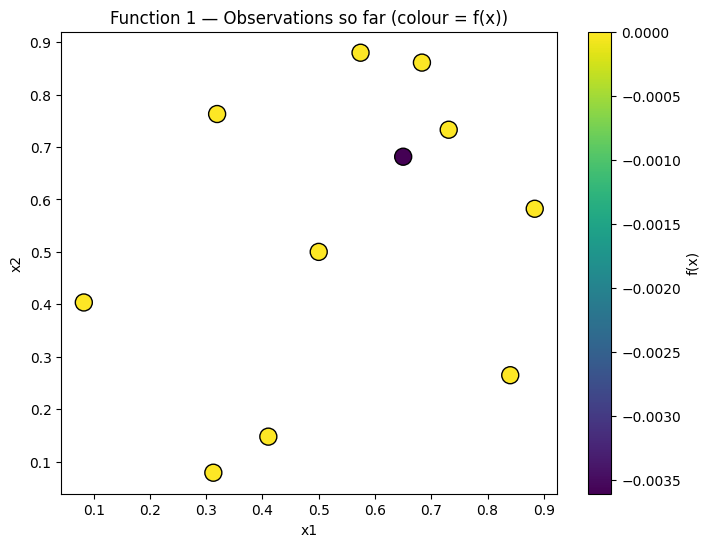

  fitted kernel: RBF(length_scale=0.05)
  current best observed: x=[0.5 0.5], y=2.67529e-09
  round-2 next query: [0.77551  0.795918]


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [3]:
X0 = np.load('initial_data/function_1/initial_inputs.npy')
Y0 = np.load('initial_data/function_1/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[1]])
Y1 = np.array([week1_Y[1]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 1: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(X[:, 0], X[:, 1], c=Y, cmap='viridis', s=150, edgecolor='black')
plt.colorbar(sc, label='f(x)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Function 1 — Observations so far (colour = f(x))')
plt.show()

# Function 1 note: 9 of the original 10 observations are ~0 and one is meaningfully
# negative. A raw RBF fit on this data drives the LML optimizer to collapse
# length_scale to the lower bound, producing a near-constant posterior everywhere
# (see week-2 review). Bounding length_scale below prevents that collapse and keeps
# the acquisition meaningful, but the fit is still working with very little signal --
# treat this function's suggestion with more skepticism than the others and consider
# cross-checking it visually against unexplored regions, as we did for round 1.

noise_assumption = 1e-6
rbf_lengthscale = 0.1
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

n_points = 50  # per dimension -- 50x50 = 2500 total grid points
x1_grid = np.linspace(0, 1, n_points)
x2_grid = np.linspace(0, 1, n_points)
X1_, X2_ = np.meshgrid(x1_grid, x2_grid)
candidates = np.column_stack([X1_.ravel(), X2_.ravel()])

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


## Function 2

Function 2: X shape=(11, 2), Y shape=(11,), dims=2
  Y range: [-0.06913, 0.6112]


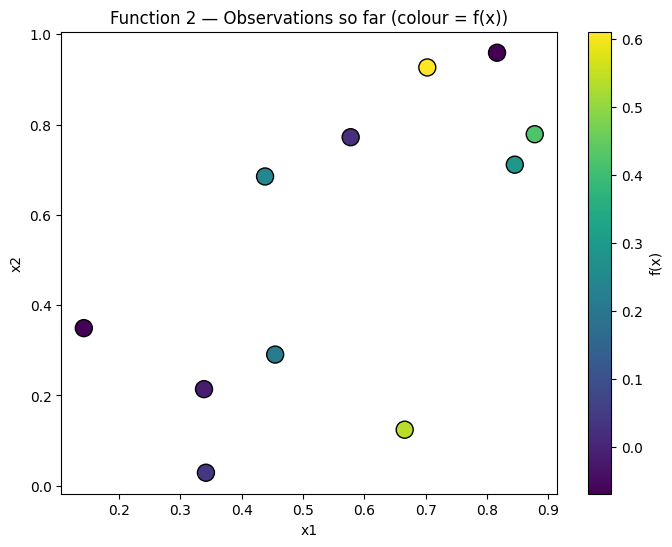

  fitted kernel: RBF(length_scale=0.05)
  current best observed: x=[0.7026 0.9266], y=0.611205
  round-2 next query: [0.673469 0.897959]


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [4]:
X0 = np.load('initial_data/function_2/initial_inputs.npy')
Y0 = np.load('initial_data/function_2/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[2]])
Y1 = np.array([week1_Y[2]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 2: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(X[:, 0], X[:, 1], c=Y, cmap='viridis', s=150, edgecolor='black')
plt.colorbar(sc, label='f(x)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Function 2 — Observations so far (colour = f(x))')
plt.show()

noise_assumption = 1e-6
rbf_lengthscale = 0.1
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

n_points = 50  # per dimension -- 50x50 = 2500 total grid points
x1_grid = np.linspace(0, 1, n_points)
x2_grid = np.linspace(0, 1, n_points)
X1_, X2_ = np.meshgrid(x1_grid, x2_grid)
candidates = np.column_stack([X1_.ravel(), X2_.ravel()])

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


## Function 3

In [5]:
X0 = np.load('initial_data/function_3/initial_inputs.npy')
Y0 = np.load('initial_data/function_3/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[3]])
Y1 = np.array([week1_Y[3]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 3: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.1
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 3: X shape=(16, 3), Y shape=(16,), dims=3
  Y range: [-0.3989, -0.02725]
  fitted kernel: RBF(length_scale=0.198)


  current best observed: x=[0.406  0.4106 0.4908], y=-0.0272537
  round-2 next query: [0.377732 0.08922  0.423517]


## Function 4

In [6]:
X0 = np.load('initial_data/function_4/initial_inputs.npy')
Y0 = np.load('initial_data/function_4/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[4]])
Y1 = np.array([week1_Y[4]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 4: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.1
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 4: X shape=(31, 4), Y shape=(31,), dims=4
  Y range: [-32.63, -0.3933]
  fitted kernel: RBF(length_scale=0.522)
  current best observed: x=[0.3949 0.4254 0.3524 0.4649], y=-0.393294
  round-2 next query: [0.384555 0.428957 0.409752 0.392875]


## Function 5

In [7]:
X0 = np.load('initial_data/function_5/initial_inputs.npy')
Y0 = np.load('initial_data/function_5/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[5]])
Y1 = np.array([week1_Y[5]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 5: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.1
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 5: X shape=(21, 4), Y shape=(21,), dims=4
  Y range: [0.1129, 1703]


  fitted kernel: RBF(length_scale=0.382)
  current best observed: x=[0.3238 0.7808 0.9523 0.9521], y=1703.15
  round-2 next query: [0.532623 0.594318 0.990109 0.985016]


## Function 6

In [8]:
X0 = np.load('initial_data/function_6/initial_inputs.npy')
Y0 = np.load('initial_data/function_6/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[6]])
Y1 = np.array([week1_Y[6]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 6: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.5
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 6: X shape=(21, 5), Y shape=(21,), dims=5
  Y range: [-2.571, -0.4104]
  fitted kernel: RBF(length_scale=0.497)


  current best observed: x=[0.3453 0.3284 0.4128 0.7275 0.0963], y=-0.410364
  round-2 next query: [0.313541 0.259869 0.535241 0.987761 0.214623]


## Function 7

In [9]:
X0 = np.load('initial_data/function_7/initial_inputs.npy')
Y0 = np.load('initial_data/function_7/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[7]])
Y1 = np.array([week1_Y[7]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 7: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.5
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 7: X shape=(31, 6), Y shape=(31,), dims=6
  Y range: [0.002701, 2.068]


  fitted kernel: RBF(length_scale=0.285)
  current best observed: x=[0.0572 0.4246 0.3947 0.208  0.3791 0.6532], y=2.06794
  round-2 next query: [0.142611 0.367475 0.49149  0.152728 0.36191  0.68565 ]


## Function 8

In [10]:
X0 = np.load('initial_data/function_8/initial_inputs.npy')
Y0 = np.load('initial_data/function_8/initial_outputs.npy')

# fold in the round-1 query + result so round 2 is informed by it
X1 = np.array([week1_X[8]])
Y1 = np.array([week1_Y[8]])
X = np.vstack([X0, X1])
Y = np.concatenate([Y0, Y1])

n_dims = X.shape[1]
print(f"Function 8: X shape={X.shape}, Y shape={Y.shape}, dims={n_dims}")
print(f"  Y range: [{Y.min():.4g}, {Y.max():.4g}]")

noise_assumption = 1e-6
rbf_lengthscale = 0.5
beta = 1.96

# length_scale_bounds keeps the optimizer from collapsing to a degenerate near-zero
# solution on flat/noisy-looking data (observed for Functions 1 and 7 with default bounds)
kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds=(0.05, 2.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=noise_assumption, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=RNG_SEED)
model.fit(X, Y)
print(f"  fitted kernel: {model.kernel_}")

# high-D input -> random candidates instead of a meshgrid
n_candidates = 20000
rng = np.random.RandomState(RNG_SEED)
candidates = rng.uniform(low=0, high=1, size=(n_candidates, n_dims))

post_mean, post_std = model.predict(candidates, return_std=True)
ucb_scores = post_mean + beta * post_std
best_idx = np.argmax(ucb_scores)
next_x = candidates[best_idx]

best_obs_idx = np.argmax(Y)
print(f"  current best observed: x={X[best_obs_idx].round(4)}, y={Y[best_obs_idx]:.6g}")
print("  round-2 next query:", next_x.round(6))


Function 8: X shape=(41, 8), Y shape=(41,), dims=8
  Y range: [5.592, 9.867]
  fitted kernel: RBF(length_scale=0.92)


  current best observed: x=[0.1584 0.0892 0.0068 0.0685 0.7796 0.3397 0.1099 0.0734], y=9.86742
  round-2 next query: [0.192332 0.148385 0.293081 0.032111 0.743423 0.258716 0.124238 0.699129]
